# Ablación de las cabezas de la red funcional
Comparación de las cabezas lineal, MLP y KAN con los modelos entrenados en `funciones/Entrenamiento_red.py` (objetivo directo): mismo codificador, mismo decodificador FPCA, parámetros de KAN y MLP igualados (diferencia ≤ 10 %), 3 semillas por cabeza y el mismo presupuesto de entrenamiento. Las funciones están en `funciones/Ablacion_cabezas.py`.

Evaluación con validación cruzada: cada curva de entrenamiento (1981–1997) se compara con la predicción del modelo entrenado sin su grupo de estaciones (5 grupos, notebook 01, configuración elegida). Las estaciones de prueba (1998–2003) no se usan.

## Configuración y datos

In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import Ablacion_arquitectura as Aa
import Ablacion_cabezas as Ac

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = Aa.preparar_datos()
print('Curvas evaluadas con validación cruzada:', D['va'].sum(), '| estaciones:', D['meta'].STATION_ID[D['va']].nunique())
display(pd.read_csv('Tablas/08_red_configuracion_elegida.csv'))
pd.read_csv('Tablas/08_red_parametros_cabezas.csv')

Curvas de validación: 117 | estaciones: 25


,cabeza,q,M,lambda,mean,std
0,KAN,8,5,100.00,99.691843,10.644825
1,MLP,8,5,0.01,98.219711,10.522763
2,lineal,8,5,100.00,122.412495,2.399474


,q,M,parametros_lineal,parametros_KAN,ocultas_MLP,parametros_MLP,diferencia_pct
0,6,5,45,884,63,887,0.339367
1,7,5,50,952,63,950,0.210084
2,8,5,55,1020,63,1013,0.686275


### Métricas
Todas las métricas se calculan frente a la curva suavizada de la estación (en mm, recortada en 0 como las predicciones). El satélite sin corregir es su curva suavizada.
- **L2_relativo**: $\|\hat y - y\| / \|y\|$ en la malla fina, promedio de las curvas.
- **KGE**: $1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}$, mediana de las curvas.
- **sesgo_%**: sesgo del acumulado anual, diferencia porcentual entre el acumulado predicho y el de la curva de la estación.
- **pico1_pentadas / pico2_pentadas**: error en la fecha del máximo de marzo–junio y de septiembre–diciembre.
- **RECM_mm**: raíz del error cuadrático medio en las 72 péntadas.

Cada cabeza se resume con la media y la desviación estándar de sus 3 semillas.

In [2]:
predicciones = Ac.predicciones_vc(D)
por_curva = Ac.tablas_por_curva(D, predicciones)
tabla_metricas = Ac.tabla_metricas(por_curva)
tabla_metricas.to_csv('Tablas/09_ablacion_cabezas_metricas.csv')
tabla_metricas.round(3)

,L2_relativo,L2_relativo_desv,KGE,KGE_desv,sesgo_%,sesgo_%_desv,pico1_pentadas,pico1_pentadas_desv,pico2_pentadas,pico2_pentadas_desv,RECM_mm,RECM_mm_desv
modelo,,,,,,,,,,,,
lineal,0.409,0.010,0.466,0.009,-10.490,1.459,3.719,0.334,1.879,0.034,15.950,0.048
MLP,0.385,0.003,0.487,0.022,-8.900,2.858,3.950,0.061,1.747,0.065,13.228,1.438
KAN,0.394,0.024,0.479,0.027,-3.513,5.957,4.397,0.098,1.671,0.033,12.476,0.651
Satélite sin corregir,0.495,NaN,0.373,NaN,-4.243,NaN,4.375,NaN,6.001,NaN,16.739,NaN


## Media y sesgo por péntada

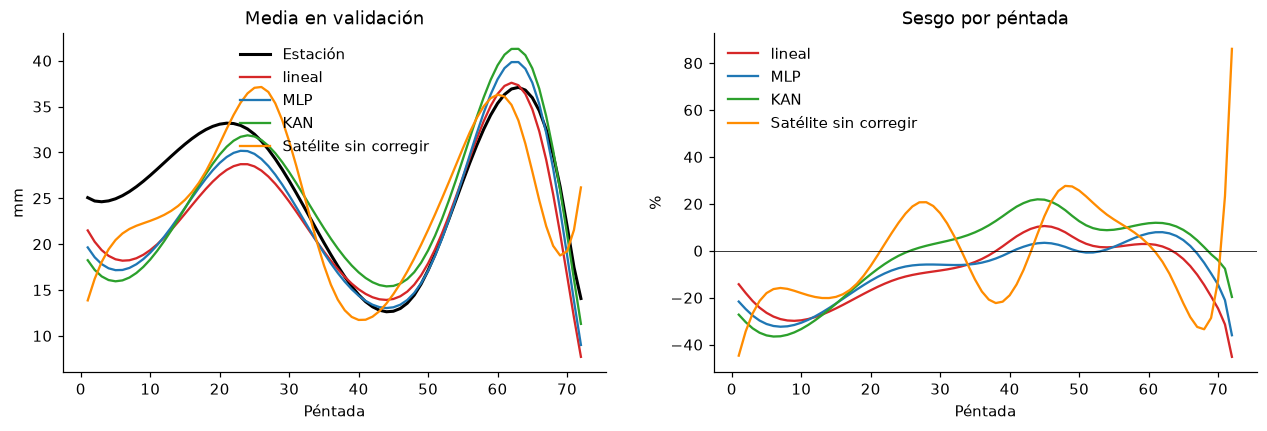

In [3]:
fig = Ac.grafica_media(D, predicciones); fig.savefig('Figuras/09_ablacion_cabezas_media_sesgo.png', dpi=150, bbox_inches='tight'); plt.show()

## ¿La red aprende más que la climatología?
Se compara cada modelo con la climatología de entrenamiento $\mu(t)$ (curva media de las curvas de entrenamiento de 1981–1997), que es lo que devolvería una red que solo aprende la media.
- **mejora_%**: reducción del error cuadrático frente a predecir $\mu(t)$ en todas las curvas.
- **curvas_mejores_%**: curvas con menor RECM que $\mu(t)$.
- **corr_anomalias**: correlación entre $\hat y - \mu$ y $y - \mu$; si la red solo devuelve la media, es 0.
- **razon_desv_anomalias**: desviación de las anomalías predichas sobre la de las observadas; menor que 1 indica predicciones encogidas hacia la media.
- **corr_acumulado**: correlación entre acumulados anuales predichos y observados (distinguir años y sitios húmedos de secos).

Cada cabeza es el promedio de sus 3 semillas.

In [4]:
tabla_media = Ac.aprendizaje_media(D, predicciones)
tabla_media.to_csv('Tablas/09_ablacion_cabezas_climatologia.csv')
tabla_media.round(3)

,RECM_mm,mejora_%,curvas_mejores_%,corr_anomalias,razon_desv_anomalias,corr_acumulado
modelo,,,,,,
lineal,15.914,34.917,65.812,0.640,0.427,0.752
MLP,12.478,59.984,78.632,0.791,0.672,0.893
KAN,11.560,65.655,71.795,0.810,0.820,0.935
Satélite sin corregir,16.739,27.993,44.444,0.529,0.553,0.692
Climatología,19.726,0.000,0.000,NaN,NaN,NaN


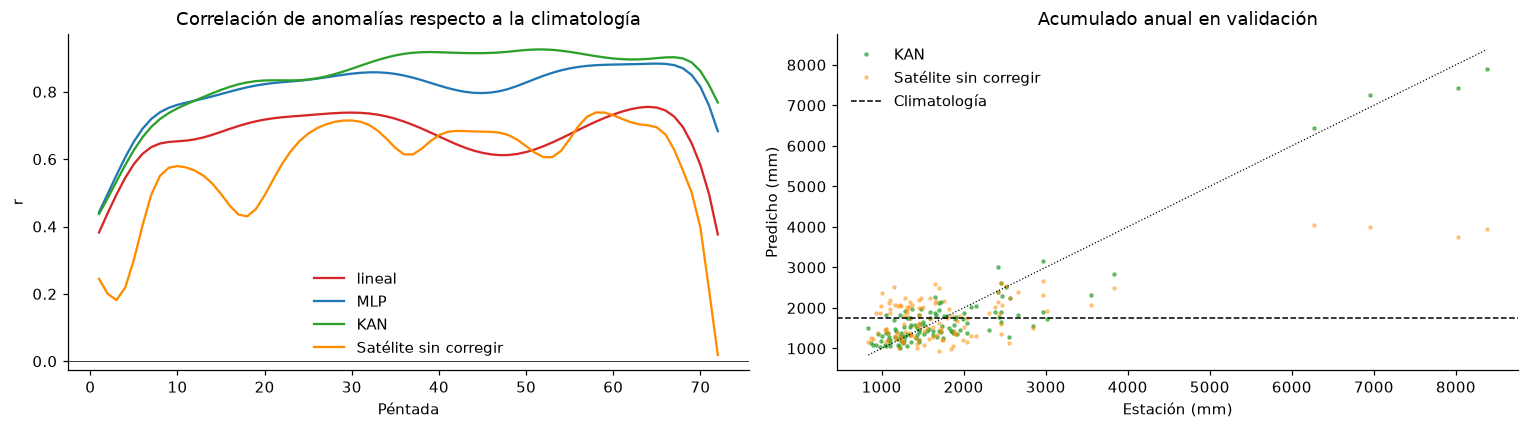

In [5]:
fig = Ac.grafica_anomalias(D, predicciones); fig.savefig('Figuras/09_ablacion_cabezas_anomalias.png', dpi=150, bbox_inches='tight'); plt.show()

## Desfase y fecha de los picos
Para cada curva se busca el rezago, entre −6 y +6 péntadas, con la mayor correlación entre la curva predicha y la de la estación (rezago > 0: la predicción va adelantada). Se reporta también el error con signo en la fecha de cada pico (> 0: el pico predicho llega tarde) además del error absoluto de la tabla de métricas.

In [6]:
tabla_rezagos, rezagos_por_curva = Ac.rezagos(D, predicciones)
tabla_rezagos.to_csv('Tablas/09_ablacion_cabezas_rezagos.csv')
tabla_rezagos.round(2)

,rezago_mediano,rezago_medio,curvas_rezago_0_%,curvas_rezago_hasta_1_%,rezago_curva_media,pico1_sesgo_pentadas,pico1_pentadas,pico2_sesgo_pentadas,pico2_pentadas
modelo,,,,,,,,,
lineal,0.0,0.74,23.93,53.85,0,2.52,3.66,-1.08,1.88
MLP,0.0,0.39,23.93,57.26,0,2.88,3.97,-0.76,1.63
KAN,0.0,0.05,22.22,56.41,0,3.53,4.26,-0.73,1.53
Satélite sin corregir,2.0,1.59,5.13,28.21,2,3.62,4.38,-0.06,6.00
Climatología,0.0,0.08,15.38,64.10,0,3.57,4.54,-0.58,1.66


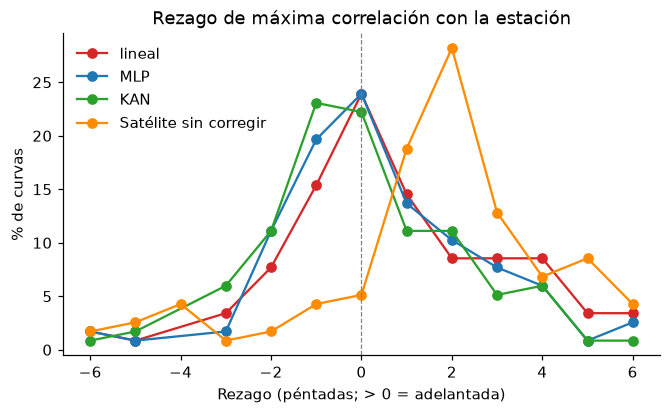

In [7]:
fig = Ac.grafica_rezagos(rezagos_por_curva); fig.savefig('Figuras/09_ablacion_cabezas_rezagos.png', dpi=150, bbox_inches='tight'); plt.show()

## Bootstrap por estaciones
Se remuestrean las estaciones de entrenamiento con reemplazo (2000 remuestreos) y cada estación aporta todas sus curvas. En cada remuestreo se calcula la métrica de cada cabeza (promedio de sus 3 semillas) y la diferencia entre cabezas. El IC del 95 % es el intervalo entre los percentiles 2,5 y 97,5 de las diferencias.

Una cabeza supera a otra solo si el IC del 95 % de la diferencia excluye el cero. En el sesgo se compara el valor absoluto.

In [8]:
remuestreos = Ac.bootstrap(D, por_curva)
comparacion = Ac.comparar(por_curva, remuestreos)
comparacion.to_csv('Tablas/09_ablacion_cabezas_bootstrap.csv', index=False)
comparacion.round(3)

,A,B,metrica,diferencia_A_menos_B,IC95_inferior,IC95_superior,conclusion
0,MLP,lineal,L2_relativo,-0.024,-0.054,0.003,Sin diferencia
1,MLP,lineal,KGE,0.021,-0.023,0.086,Sin diferencia
2,MLP,lineal,sesgo_abs_%,-1.589,-10.806,5.650,Sin diferencia
3,MLP,lineal,pico1_pentadas,0.231,-0.092,0.595,Sin diferencia
4,MLP,lineal,pico2_pentadas,-0.132,-0.226,-0.044,MLP supera a lineal
5,MLP,lineal,RECM_mm,-2.721,-6.658,0.401,Sin diferencia
6,KAN,lineal,L2_relativo,-0.015,-0.050,0.016,Sin diferencia
7,KAN,lineal,KGE,0.014,-0.048,0.087,Sin diferencia
8,KAN,lineal,sesgo_abs_%,-6.405,-17.308,3.639,Sin diferencia
9,KAN,lineal,pico1_pentadas,0.678,0.162,1.271,lineal supera a KAN


In [9]:
comparacion.pivot_table(index=['A', 'B'], columns='metrica', values='conclusion', aggfunc='first')[list(Ac.METRICAS)]

metrica                                                 L2_relativo  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                         KGE  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir                         Sin diferencia   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                          sesgo_abs_%  \
A      B                                       
KAN    MLP                    Sin diferencia   
       Satélite sin corregir  Sin diferencia   
       lineal                 Sin diferencia   
MLP    Satélite sin corregir  Sin diferencia   
       lineal                 Sin diferencia   
lineal Satélite sin corregir  Sin diferencia   

metrica                                              pico1_pentadas  \
A      B                                                              
KAN    MLP                                         MLP supera a KAN   
       Satélite sin corregir                         Sin diferencia   
       lineal                                   lineal supera a KAN   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                              pico2_pentadas  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                   KAN supera a lineal   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                   MLP supera a lineal   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                  RECM_mm  
A      B                                                          
KAN    MLP                                        Sin diferencia  
       Satélite sin corregir  KAN supera a Satélite sin corregir  
       lineal                                     Sin diferencia  
MLP    Satélite sin corregir  MLP supera a Satélite sin corregir  
       lineal                                     Sin diferencia  
lineal Satélite sin corregir                      Sin diferencia

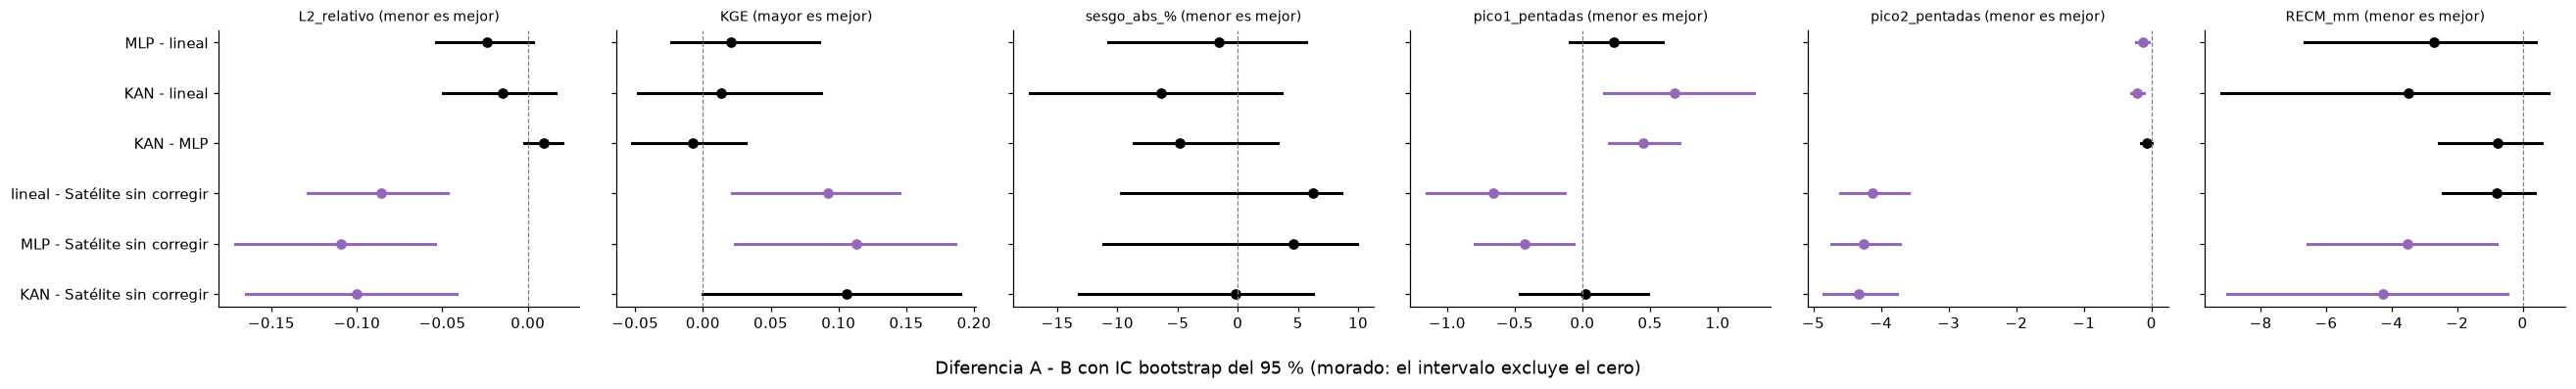

In [10]:
fig = Ac.grafica_intervalos(comparacion); fig.savefig('Figuras/09_ablacion_cabezas_bootstrap.png', dpi=150, bbox_inches='tight'); plt.show()